In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

orders_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv"
]

df_orders = pd.concat(
    [pd.read_csv(f) for f in orders_files],
    ignore_index=True
)

df_orders["order_datetime"] = pd.to_datetime(
    df_orders["order_datetime"]
)

print(df_orders.head())
print(df_orders["status"].value_counts(dropna=False))

   order_id  user_id      order_datetime  product_id     price  quantity  \
0         1     1044 2024-01-03 18:39:26          26  14038.15         1   
1         2     1079 2024-01-03 17:45:43          16   9172.60         1   
2         3     1041 2024-01-06 22:46:38          25   9035.26         2   
3         4     1083 2024-01-08 21:03:51           9  15234.33         3   
4         5     1068 2024-01-03 23:26:53          24   4134.38         2   

     status  
0  refunded  
1      paid  
2      paid  
3      paid  
4      paid  
status
paid         12032
cancelled     2212
refunded       756
Name: count, dtype: int64


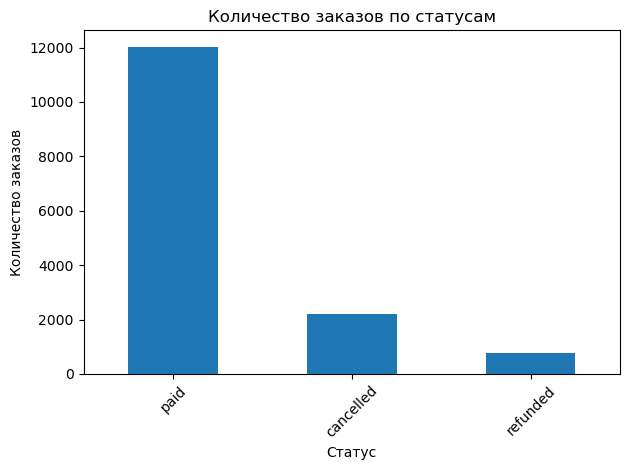

In [13]:
# Задание 1
status_counts = df_orders["status"].value_counts()

status_counts.plot(kind="bar")

plt.title("Количество заказов по статусам")
plt.xlabel("Статус")
plt.ylabel("Количество заказов")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

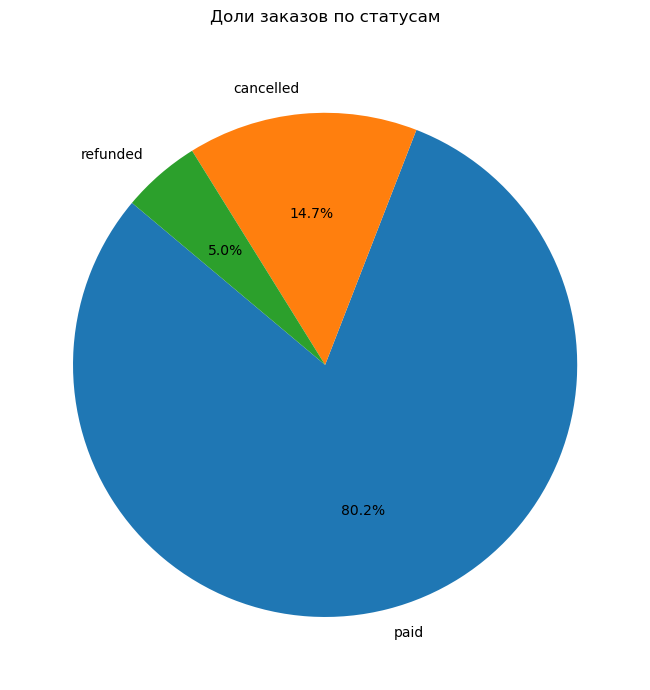

status
paid         80.21
cancelled    14.75
refunded      5.04
Name: proportion, dtype: float64


In [14]:
# Задание 2
status_shares = df_orders["status"].value_counts(normalize=True) * 100

status_shares.plot(
    kind="pie",
    autopct="%1.1f%%", 
    startangle=140,  
    figsize=(7, 7), 
)

plt.title("Доли заказов по статусам", pad=20)
plt.ylabel("") 
plt.tight_layout()
plt.show()

print(status_shares.round(2))

In [15]:
# Задание 3
status_comparison = pd.DataFrame({
    "Количество": df_orders["status"].value_counts(),
    "Доля, %": df_orders["status"].value_counts(
        normalize=True
    ) * 100
})

print(status_comparison.round(2))

           Количество  Доля, %
status                        
paid            12032    80.21
cancelled        2212    14.75
refunded          756     5.04


In [10]:
# Задание 4
most_common_status = status_counts.idxmax()
least_common_status = status_counts.idxmin()

print("Самый распространённый статус:", most_common_status)
print("Количество:", status_counts.max())

print("\nСамый редкий статус:", least_common_status)
print("Количество:", status_counts.min())

""" Ошибка интерпретации может возникнуть, если сравнивать количество заказов без учёта общего объёма данных или условий выборки."""

Самый распространённый статус: paid
Количество: 12032

Самый редкий статус: refunded
Количество: 756

Ошибка интерпретации может возникнуть, если сравнивать количество заказов без учёта общего объёма данных или условий выборки.


In [ ]:
"""
Задание 5
Типичная ошибка анализа: делать вывод о проблемности статуса только по абсолютному количеству заказов.
Для корректной оценки нужно учитывать долю статуса от общего количества заказов и контекст данных.
"""